# 06 — Final Evaluation on the Held-Out Test Set

**Protocol**
1. The model (`xgboost`, chosen by the pre-declared rule in notebook 05) and both decision thresholds (chosen on validation) were **frozen** in `artifacts/metrics/frozen_decision.json`, with SHA-256 hashes of the model files, *before* any test row was read.
2. `scripts/evaluate_test.py` evaluated the frozen model once on the 6,000 test clients. The script refuses to run twice unless forced, and it records the number of test accesses.
3. Logistic Regression, Random Forest and the dummy baseline are shown **as references only**. Nothing was re-selected or re-tuned after seeing these results.

This notebook only reads `artifacts/metrics/test_evaluation.json`.

In [1]:
import json
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from credit_risk.config import resolve_path
BLUE, ORANGE, AQUA, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#9a9a9a", "#1f1f1f", "#6b6b6b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6",
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.axisbelow": True, "figure.dpi": 110})
FIG_DIR = resolve_path("reports/figures")
pd.set_option("display.width", 200); pd.set_option("display.precision", 4)
T = json.loads(resolve_path("artifacts/metrics/test_evaluation.json").read_text())
frozen = T["frozen_decision"]
print("Test clients:", T["n_test"], "| default rate:", round(T["test_default_rate"], 4), "| test accesses:", T["test_access_count"])
print("Frozen at", frozen["frozen_utc"], "->", frozen["selected_model"], frozen["thresholds"])

Test clients: 6000 | default rate: 0.2212 | test accesses: 1
Frozen at 2026-10-29T21:37:02+00:00 -> xgboost {'f2_unconstrained': 0.135, 'f2_capacity_30pct': 0.23, 'reference_0_5': 0.5}


## 1. Validation vs test

In [2]:
rows = []
for m, e in T["models"].items():
    for split, pm in [("validation", e["validation_probability_metrics"]), ("test", e["probability_metrics"])]:
        rows.append({"model": m, "split": split, **{k: pm[k] for k in ["roc_auc", "pr_auc", "brier", "log_loss", "expected_calibration_error", "mean_predicted_pd"]}})
pd.DataFrame(rows).set_index(["model", "split"])

roc_auc  pr_auc   brier  log_loss  expected_calibration_error  mean_predicted_pd
model         split                                                                                       
xgboost       validation   0.7879  0.5631  0.1333    0.4247                      0.0152             0.2186
              test         0.7833  0.5645  0.1342    0.4271                      0.0071             0.2209
logreg        validation   0.7798  0.5473  0.1345    0.4299                      0.0165             0.2184
              test         0.7707  0.5275  0.1377    0.4380                      0.0127             0.2203
random_forest validation   0.7841  0.5568  0.1341    0.4270                      0.0128             0.2186
              test         0.7785  0.5580  0.1349    0.4296                      0.0152             0.2209
dummy_prior   validation   0.5000  0.2212  0.1723    0.5284                      0.0208             0.2212
              test         0.5000  0.2212  0.1723    0.5284                      0.0189             0.2212

In [3]:
ci = pd.DataFrame({m: {f"{k}_{b}": e["confidence_intervals"][k][b] for k in ["roc_auc", "pr_auc", "brier"] for b in ["low", "high"]}
                   for m, e in T["models"].items()}).T
ci

,roc_auc_low,roc_auc_high,pr_auc_low,pr_auc_high,brier_low,brier_high
xgboost,0.7699,0.7984,0.5382,0.5948,0.1281,0.1399
logreg,0.7553,0.7863,0.5005,0.5589,0.1315,0.1437
random_forest,0.7646,0.7937,0.5302,0.5885,0.1287,0.1407
dummy_prior,0.5000,0.5000,0.2107,0.2322,0.1664,0.1784


## 2. Paired comparisons on the test set (1,000 bootstrap resamples)

In [4]:
pd.DataFrame(T["paired_comparisons"])[["model_a", "model_b", "metric", "difference", "low", "high", "p_value_two_sided"]]

,model_a,model_b,metric,difference,low,high,p_value_two_sided
0,xgboost,logreg,roc_auc,0.0126,0.0066,0.0193,0.000
1,xgboost,logreg,pr_auc,0.0370,0.0213,0.0518,0.000
2,xgboost,logreg,brier,-0.0035,-0.0049,-0.0022,0.000
3,xgboost,random_forest,roc_auc,0.0048,0.0024,0.0073,0.000
4,xgboost,random_forest,pr_auc,0.0065,0.0011,0.0115,0.020
5,xgboost,random_forest,brier,-0.0007,-0.0013,-0.0002,0.012


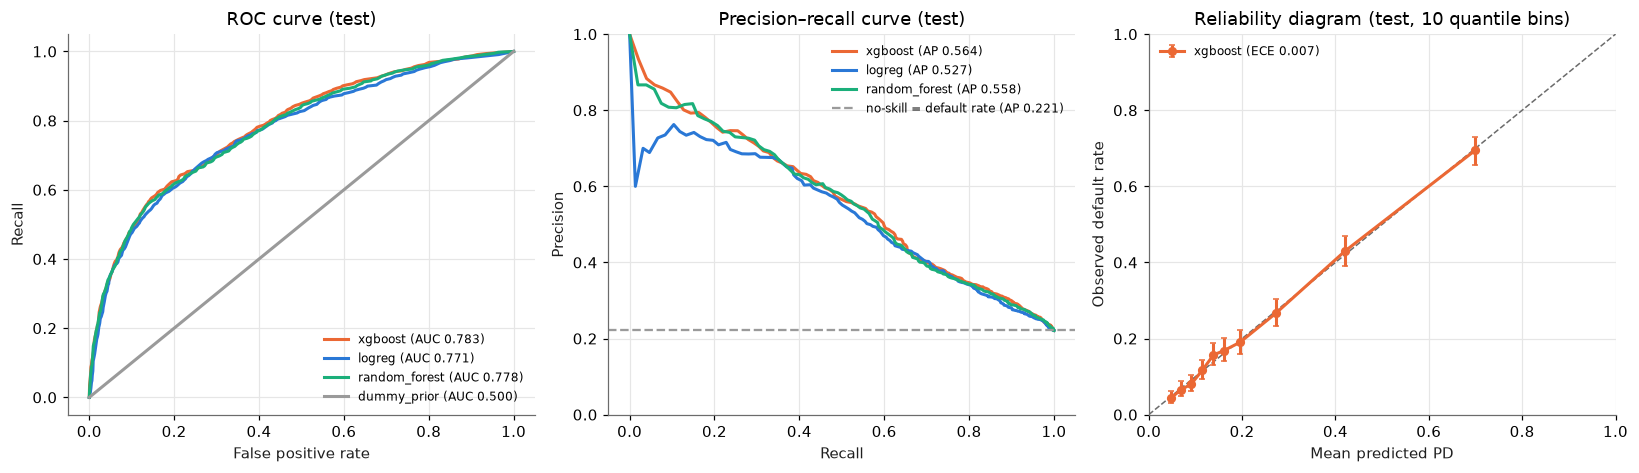

In [5]:
COL = {"xgboost": ORANGE, "random_forest": AQUA, "logreg": BLUE, "dummy_prior": GREY}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for m, e in T["models"].items():
    c, pm = e["curves"], e["probability_metrics"]
    axes[0].plot(c["roc_fpr"], c["roc_tpr"], color=COL[m], lw=2, label=f"{m} (AUC {pm['roc_auc']:.3f})")
    if m == "dummy_prior":  # constant scores: the PR "curve" is the horizontal no-skill line
        axes[1].axhline(T["test_default_rate"], color=GREY, ls="--", lw=1.5, label=f"no-skill = default rate (AP {pm['pr_auc']:.3f})")
    else:
        axes[1].plot(c["pr_recall"], c["pr_precision"], color=COL[m], lw=2, label=f"{m} (AP {pm['pr_auc']:.3f})")
axes[0].set(title="ROC curve (test)", xlabel="False positive rate", ylabel="Recall")
axes[1].set(title="Precision–recall curve (test)", xlabel="Recall", ylabel="Precision", ylim=(0, 1))
t = pd.DataFrame(T["models"]["xgboost"]["calibration_table"])
axes[2].plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
axes[2].errorbar(t["mean_predicted"], t["observed_rate"], yerr=[t["observed_rate"] - t["observed_low"], t["observed_high"] - t["observed_rate"]],
                 color=ORANGE, lw=2, marker="o", ms=5, capsize=2, label=f"xgboost (ECE {T['models']['xgboost']['probability_metrics']['expected_calibration_error']:.3f})")
axes[2].set(title="Reliability diagram (test, 10 quantile bins)", xlabel="Mean predicted PD", ylabel="Observed default rate", xlim=(0, 1), ylim=(0, 1))
for ax in axes: ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "06_test_roc_pr_calibration.png", bbox_inches="tight")

## 3. Frozen decision rules applied to the test set

In [6]:
val = json.loads(resolve_path("artifacts/metrics/xgboost.json").read_text())
val_rules = {"f2_unconstrained": val["threshold_metrics"], "f2_capacity_30pct": val["threshold_metrics_capacity"], "reference_0_5": val["threshold_metrics_at_0_5"]}
rows = []
for rule, tm in T["models"]["xgboost"]["threshold_metrics"].items():
    for split, m in [("validation", val_rules[rule]), ("test", tm)]:
        rows.append({"rule": rule, "split": split, **{k: m[k] for k in ["threshold", "recall", "precision", "f1", "f2", "flagged_rate"]}, **m["confusion_matrix"]})
pd.DataFrame(rows).set_index(["rule", "split"])

threshold  recall  precision      f1      f2  flagged_rate    tn    fp   fn    tp
rule              split                                                                                        
f2_unconstrained  validation      0.135  0.8493     0.3332  0.4787  0.6484        0.5637  2418  2255  200  1127
                  test            0.135  0.8433     0.3306  0.4750  0.6436        0.5642  2407  2266  208  1119
f2_capacity_30pct validation      0.230  0.6217     0.4696  0.5350  0.5839        0.2928  3741   932  502   825
                  test            0.230  0.6255     0.4703  0.5369  0.5867        0.2942  3738   935  497   830
reference_0_5     validation      0.500  0.3602     0.6888  0.4730  0.3982        0.1157  4457   216  849   478
                  test            0.500  0.3564     0.6662  0.4644  0.3930        0.1183  4436   237  854   473

## 4. Risk segmentation (xgboost, test)

,band,clients,defaults,observed_rate,mean_pd,share_of_clients,share_of_defaults
0,"[0.0, 0.05)",363,10,0.0275,0.0427,0.0605,0.0075
1,"[0.05, 0.1)",1372,97,0.0707,0.0742,0.2287,0.0731
2,"[0.1, 0.2)",2236,350,0.1565,0.1448,0.3727,0.2638
3,"[0.2, 0.4)",1125,304,0.2702,0.2839,0.1875,0.2291
4,"[0.4, 1.0)",904,566,0.6261,0.6247,0.1507,0.4265


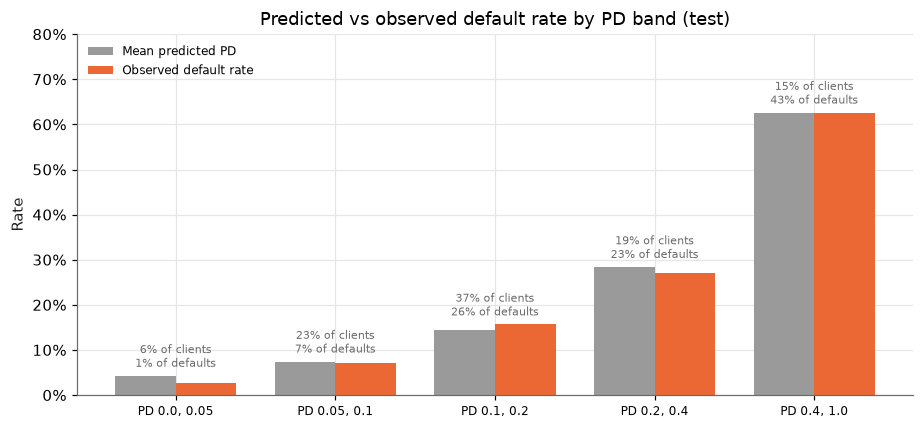

In [7]:
bands = pd.DataFrame(T["risk_bands"])
fig, ax = plt.subplots(figsize=(8.5, 4))
x = np.arange(len(bands)); w = 0.38
ax.bar(x - w / 2, bands["mean_pd"], w, color=GREY, label="Mean predicted PD")
ax.bar(x + w / 2, bands["observed_rate"], w, color=ORANGE, label="Observed default rate")
for i, r in bands.iterrows():
    ax.text(i, max(r["mean_pd"], r["observed_rate"]) + 0.02, f"{r['share_of_clients']:.0%} of clients\n{r['share_of_defaults']:.0%} of defaults", ha="center", fontsize=7, color=MUTED)
ax.set_xticks(x, [b.replace("[", "PD ").replace(")", "") for b in bands["band"]], fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_ylim(0, 0.8)
ax.set(title="Predicted vs observed default rate by PD band (test)", ylabel="Rate")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIG_DIR / "06_test_risk_bands.png", bbox_inches="tight")
bands

## 5. Who is misclassified? (xgboost, frozen 30%-capacity threshold, test; medians)

In [8]:
pd.DataFrame(T["error_profiles_capacity_threshold"]).set_index("outcome")

,clients,LIMIT_BAL,AGE,PAY_1,months_delayed,max_delay,utilization_mean,payment_to_bill_ratio,pd
outcome,,,,,,,,,
TP,830,80000.0,34.0,2.0,3.0,2.0,0.5475,0.0446,0.5779
FP,935,80000.0,34.0,1.0,2.0,2.0,0.4431,0.0543,0.3520
FN,497,150000.0,36.0,0.0,0.0,0.0,0.2129,0.1443,0.1447
TN,3738,170000.0,34.0,0.0,0.0,0.0,0.2202,0.1442,0.1112


## Conclusions

**Generalisation**
- The frozen XGBoost model generalises: test ROC-AUC 0.783 [0.770, 0.798], PR-AUC 0.564 [0.538, 0.595], Brier 0.1342, ECE 0.007. Validation gave 0.788, 0.563 and 0.1333.
- The frozen thresholds behave as on validation. The 30%-capacity rule flags 29.4% of test clients, with recall 0.625 and precision 0.470. The unconstrained F2 rule flags 56%, with recall 0.84.

**Comparison with the references (test, paired bootstrap)**
- XGBoost outperforms Logistic Regression: ΔPR-AUC +0.037 [+0.021, +0.052], ΔROC-AUC +0.013 [+0.007, +0.019].
- Against Random Forest the difference is small: ΔPR-AUC +0.007 [+0.001, +0.012]. Training-set CV found them equivalent, so the honest summary is that **XGBoost and Random Forest perform similarly, and both are better than Logistic Regression.**

**Calibration and segmentation**
- The PDs are reliable across the range: in every band, the mean predicted PD is within about 1.5 points of the observed rate.
- The top band (PD ≥ 40%) holds 15% of clients and 43% of all defaults.

**Error analysis**
- Missed defaulters (FN) look like non-defaulters on every available variable: no recorded delay (`PAY_1` = 0, `months_delayed` = 0), higher limits, lower utilisation.
- Their defaults are not preceded by warning signs that the data captures. That is a limitation of the information in the dataset, which no threshold or resampling scheme can fix.
- False positives (FP) do show delay history and higher utilisation. They are clients who look risky but did not default in the following month.

**Limitations**
- These results come from one random split of one historical cross-section (Taiwan, 2005). They do not establish temporal stability or performance on a current portfolio.
- The default flag is the UCI definition, not a regulatory definition of default.
- The thresholds are screening rules under stated assumptions, not credit decisions.
- The test set has now been used. Any further model change would need new, untouched data to be evaluated without bias.